# Un modelo completo, paso a paso: regresión logística en sonidos cardíacos

Tu directora pidió, para antes del miércoles, **un modelo desarrollado** indicando:
1. el dataset usado;
2. las dimensiones de la base y de entrenamiento (train) y prueba (test);
3. las categorías de la variable a predecir;
4. las instrucciones usadas (ella escribió R, pero vos trabajás en Python);
5. las métricas obtenidas, **entendiéndolas**.

En la reunión agregó una cosa más: "jugar" con el umbral. Mostrar que el AUC
no cambia al moverlo, que la sensibilidad y la especificidad sí cambian (y en
sentidos opuestos), armar una tabla con qué pasa en cada umbral y calcular el
índice de Youden.

Esta notebook sigue exactamente ese orden. Cada sección tiene el código (las
"instrucciones") y una explicación con tus números. La idea es que la leas,
la corras, cambies cosas y, cuando la entiendas, escribas con tus palabras el
documento para tu directora.

**Modelo:** regresión logística. **Subconjunto:** sonidos cardíacos. Es donde
el umbral importa de verdad: en pulmonares el modelo separa casi perfecto y
mover el umbral casi no cambia nada (lo podés comprobar en el "Tu turno").

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.paths import OUT_DIR

warnings.filterwarnings("ignore")

SUBCONJUNTO = "hs"   # "hs" = cardíacos, "ls" = pulmonares
AZUL, NARANJA, AQUA, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6})

## 1. El dataset

**HLS-CMDS** (Torabi, Shirani y Reilly, 2025) es un conjunto público de sonidos
cardíacos y pulmonares grabados sobre un **maniquí clínico** con un
estetoscopio digital, a 4000 muestras por segundo. Tiene tres subconjuntos:
sonidos cardíacos, sonidos pulmonares y mezclas de los dos. Se distribuye con
licencia CC BY 4.0, que permite usarlo citando la fuente.

Del audio no se entrena directamente: primero cada grabación se convierte en
una fila de números (las **características**), con la extracción corregida de
la notebook 11. Esa tabla es la que se lee acá.

In [2]:
datos = pd.read_csv(OUT_DIR / f"{SUBCONJUNTO}_features_corregidas.csv")
print("Archivo:", f"outputs/{SUBCONJUNTO}_features_corregidas.csv")
print("Dimensiones de la tabla completa:", datos.shape)
datos[["file_id", "label", "label_binary", "mfcc_1_mean", "spectral_centroid_mean", "rms_mean"]].head()

Archivo: outputs/hs_features_corregidas.csv
Dimensiones de la tabla completa: (50, 104)


,file_id,label,label_binary,mfcc_1_mean,spectral_centroid_mean,rms_mean
0,F_N_RC,Normal,0,-866.51110,197.294526,0.000889
1,F_N_LC,Normal,0,-826.65380,124.098381,0.002454
2,M_N_RUSB,Normal,0,-753.58606,138.139088,0.004103
3,F_N_LUSB,Normal,0,-807.46550,154.331623,0.003403
4,F_N_LLSB,Normal,0,-792.29820,163.807708,0.003320


Cada **fila** es una grabación (un foco de auscultación de un caso del
maniquí). Las columnas son el identificador (`file_id`), el tipo de sonido
(`label`), la etiqueta binaria (`label_binary`) y las características.

## 2. La variable a predecir

El dataset trae el **tipo** de sonido: normal o alguna de nueve patologías.
Para este trabajo la variable se vuelve **binaria**:
- **0 = normal**;
- **1 = patológico** (cualquier tipo que no sea normal).

In [3]:
print("Tipos de sonido en el dataset:")
print(datos["label"].value_counts().to_string())
print("\nVariable a predecir (binaria):")
conteo = datos["label_binary"].value_counts().sort_index()
print(f"  0 = normal:     {conteo[0]} grabaciones ({conteo[0] / len(datos):.0%})")
print(f"  1 = patológico: {conteo[1]} grabaciones ({conteo[1] / len(datos):.0%})")

Tipos de sonido en el dataset:
label
Normal                   9
Mid Systolic Murmur      7
Late Diastolic Murmur    6
Early Systolic Murmur    6
S3                       5
Late Systolic Murmur     5
Atrial Fibrillation      4
Tachycardia              3
AV Block                 3
S4                       2

Variable a predecir (binaria):
  0 = normal:     9 grabaciones (18%)
  1 = patológico: 41 grabaciones (82%)


**Las clases están desbalanceadas:** hay 9 normales y 41 patológicos. Esto
tiene dos consecuencias que vas a ver a lo largo de la notebook:
- un "modelo" que dijera siempre "patológico" acertaría el 82 % de las veces
  sin reconocer ningún normal, así que la **exactitud** (el porcentaje de
  aciertos) engaña;
- lo difícil es reconocer a los **normales**, porque hay pocos para aprender
  cómo son.

## 3. La base: dimensiones

La base que entra al modelo es una matriz **X** de 50 filas (grabaciones) por
101 columnas (características), más un vector **y** con la etiqueta de cada
grabación.

In [4]:
X = datos.drop(columns=["file_id", "label", "label_binary"])
y = datos["label_binary"].values
print("X (características):", X.shape, "   y (etiqueta):", y.shape)

grupos = {"MFCC (media, desvío, máximo y mínimo de 13 coeficientes)": X.columns.str.match(r"mfcc_\d+_"),
          "Delta de los MFCC (cómo cambian en el tiempo)": X.columns.str.startswith("mfcc_delta"),
          "Centroide, ancho de banda y rolloff espectral": X.columns.str.match(r"spectral_(centroid|bandwidth|rolloff)"),
          "Contraste espectral (5 bandas)": X.columns.str.startswith("spectral_contrast"),
          "Planitud espectral": X.columns.str.startswith("spectral_flatness"),
          "Cruces por cero": X.columns.str.startswith("zcr"),
          "Energía (RMS)": X.columns.str.startswith("rms")}
print()
for nombre, mascara in grupos.items():
    print(f"{mascara.sum():>4}  {nombre}")
print(f"{sum(m.sum() for m in grupos.values()):>4}  total")

X (características): (50, 101)    y (etiqueta): (50,)

  52  MFCC (media, desvío, máximo y mínimo de 13 coeficientes)
  26  Delta de los MFCC (cómo cambian en el tiempo)
   6  Centroide, ancho de banda y rolloff espectral
  10  Contraste espectral (5 bandas)
   2  Planitud espectral
   2  Cruces por cero
   3  Energía (RMS)
 101  total


Qué describe cada grupo, en una línea:
- **MFCC:** un resumen del timbre, la "forma" del espectro en una escala
  parecida a la del oído.
- **Delta:** cuánto cambian los MFCC de un instante al siguiente.
- **Centroide, ancho de banda y rolloff:** dónde está la energía (grave o
  aguda) y cuán repartida está.
- **Contraste espectral:** la diferencia entre picos y valles del espectro en
  cada banda (un sonido con soplo llena los valles).
- **Planitud:** si el sonido se parece más a un ruido (plano) o a un tono.
- **Cruces por cero:** cuántas veces la señal cruza el cero (sube con lo agudo).
- **RMS:** el volumen.

Cada una se calcula en tramos cortos de 93 ms y después se resume en toda la
grabación (media, desvío, máximo, mínimo).

**Hay más columnas (101) que filas (50).** A esto se lo llama p ≫ n, y es la
principal amenaza del trabajo: con tantas columnas, un modelo flexible podría
"memorizar" las 50 grabaciones en lugar de aprender el patrón. Por eso se usa
un modelo simple y regularizado (sección 5) y se lo evalúa siempre con
grabaciones que no vio (sección 4).

## 4. Entrenamiento y prueba

Para saber si el modelo sirve hay que probarlo con grabaciones que **no usó
para aprender**: si lo evaluáramos con las mismas, sería como tomar un examen
con las preguntas que ya estudiaste.

**¿Por qué no una sola división 80/20?** Con una división fija, la prueba
tendría 10 grabaciones y solo **2 normales**. La especificidad podría valer
0 %, 50 % o 100 %, nada más, y dependería de qué dos normales tocaron.

**Validación cruzada de 5 particiones.** Se dividen las 50 grabaciones en 5
grupos de 10. Se entrena con 4 grupos (40 grabaciones) y se prueba con el que
quedó afuera (10); se repite 5 veces, cambiando el grupo de prueba. Al final,
**cada grabación fue probada una vez** por un modelo que no la vio. Es
**estratificada**: cada grupo mantiene la proporción de normales.

In [5]:
particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
filas = []
for i, (entrenamiento, prueba) in enumerate(particiones.split(X, y), 1):
    filas.append({"partición": i,
                  "train: grabaciones": len(entrenamiento), "train: normales": int((y[entrenamiento] == 0).sum()),
                  "test: grabaciones": len(prueba), "test: normales": int((y[prueba] == 0).sum())})
pd.DataFrame(filas).set_index("partición")

,train: grabaciones,train: normales,test: grabaciones,test: normales
partición,,,,
1,40,7,10,2
2,40,7,10,2
3,40,7,10,2
4,40,7,10,2
5,40,8,10,1


En cada partición: **train = 40 × 101** (7 u 8 normales) y **test = 10 × 101**
(1 o 2 normales). Todo el procedimiento se repite **3 veces** con distintos
sorteos de los grupos, y las métricas finales son el promedio (sección 10).

*Una aclaración que te pueden preguntar:* las grabaciones de un mismo caso del
maniquí (distintos focos del mismo sonido) pueden caer una en train y otra en
test. Eso podría inflar el resultado si el modelo reconociera a la grabación
"hermana". Lo medimos con el control de pseudo-casos (notebooks 07 y 10): en
cardíacos no hay fuga medible.

## 5. El modelo y las instrucciones

**Cómo decide la regresión logística.** Para cada grabación calcula un puntaje
que es una suma ponderada de sus características:

z = b + w₁·x₁ + w₂·x₂ + … + w₁₀₁·x₁₀₁

y lo transforma en una probabilidad de ser patológica con la función
sigmoide, p = 1 / (1 + e⁻ᶻ), que lleva cualquier número a un valor entre 0 y
1. Lo que **aprende** son los pesos w: uno por característica. Un peso
positivo empuja hacia "patológico"; uno negativo, hacia "normal".

**Las tres decisiones del código:**
- **Escalado** (`StandardScaler`): lleva cada característica a media 0 y
  desvío 1, para que los pesos sean comparables. Va **dentro** del pipeline,
  así que en cada partición se calcula solo con el train (si se calculara con
  las 50 grabaciones, el test "filtraría" información al entrenamiento).
- **`class_weight="balanced"`**: como hay pocos normales, equivocarse con uno
  cuesta más. Cada normal pesa n / (2 · n_normales) ≈ 2,8 y cada patológico
  n / (2 · n_patológicos) ≈ 0,6: un normal "vale" unas 4,6 veces más. Así el
  modelo no se acomoda a decir siempre "patológico".
- **`C=1.0`**: la regularización L2. Castiga los pesos grandes y los achica
  hacia cero, lo que hace al modelo más estable con p ≫ n. Se usó el valor por
  defecto, fijado de antemano (en la notebook 14, C = 0,1 dio lo mismo).

**Las instrucciones** (esto es lo que corresponde a "las instrucciones de R"
del mail):

In [6]:
X = datos.drop(columns=["file_id", "label", "label_binary"])   # 50 x 101
y = datos["label_binary"].values                                # 0 = normal, 1 = patológico

modelo = Pipeline([
    ("escalado", StandardScaler()),
    ("regresion_logistica", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
])

particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
prob = cross_val_predict(modelo, X, y, cv=particiones, method="predict_proba")[:, 1]

`cross_val_predict` hace las 5 particiones de la sección 4: en cada una
entrena el pipeline con las 40 grabaciones de train y calcula la probabilidad
de las 10 de test. El resultado, `prob`, tiene **una probabilidad por
grabación**, siempre calculada por un modelo que no la vio. Algunas:

In [7]:
vista = pd.DataFrame({"grabación": datos["file_id"], "tipo": datos["label"], "real (0/1)": y, "probabilidad": prob})
pd.concat([vista[vista["real (0/1)"] == 0].sort_values("probabilidad"),
           vista[vista["real (0/1)"] == 1].sort_values("probabilidad").head(6)]).round(3)

,grabación,tipo,real (0/1),probabilidad
2,M_N_RUSB,Normal,0,0.003
5,F_N_A,Normal,0,0.013
8,F_N_RUSB,Normal,0,0.040
10,M_N_LC,Normal,0,0.306
1,F_N_LC,Normal,0,0.330
4,F_N_LLSB,Normal,0,0.342
3,F_N_LUSB,Normal,0,0.348
0,F_N_RC,Normal,0,0.434
43,M_N_LLSB,Normal,0,0.999
33,M_AVB_LLSB,AV Block,1,0.153


Arriba están los 9 normales y los 6 patológicos con menor probabilidad. Fijate
que **la mayoría de los normales tiene probabilidades bajas**, pero no todos:
hay un normal con probabilidad muy alta (el modelo lo "ve" como patológico) y
algunos patológicos con probabilidad baja. Esos casos son los errores que
vienen a continuación. Mirá además **qué** patológicos tienen la probabilidad
más baja: bloqueo AV y fibrilación auricular, es decir, **arritmias**. Es lo
que vimos en la notebook 13: las características actuales no capturan bien el
ritmo.

## 6. Las métricas con el umbral de 0,5

Para pasar de una probabilidad a una decisión hace falta un **umbral**: si la
probabilidad es mayor o igual al umbral, la grabación se clasifica como
patológica. El valor por defecto es 0,5.

**La matriz de confusión** cruza la clase real con la predicha:
- **verdaderos positivos (VP):** patológicos detectados;
- **falsos negativos (FN):** patológicos que el modelo llamó normales (una
  patología no detectada);
- **verdaderos negativos (VN):** normales reconocidos como normales;
- **falsos positivos (FP):** normales que el modelo llamó patológicos (un
  estudio de más).

In [8]:
def metricas(y, prob, umbral):
    vn, fp, fn, vp = confusion_matrix(y, (prob >= umbral).astype(int), labels=[0, 1]).ravel()
    s, e = vp / (vp + fn), vn / (vn + fp)
    return {"umbral": umbral, "AUC": roc_auc_score(y, prob), "exactitud": (vp + vn) / len(y), "S": s, "E": e,
            "normales reconocidos": f"{vn} de {vn + fp}", "patológicos detectados": f"{vp} de {vp + fn}",
            "Youden (S + E − 1)": s + e - 1, "exactitud balanceada": (s + e) / 2}


pred = (prob >= 0.5).astype(int)
print(pd.crosstab(pd.Series(y, name="real").map({0: "normal", 1: "patológico"}),
                  pd.Series(pred, name="predicho").map({0: "normal", 1: "patológico"})))
m = metricas(y, prob, 0.5)
print(f"\nExactitud            = (VP + VN) / total  = {m['exactitud']:.2f}")
print(f"Sensibilidad (S)     = VP / (VP + FN)     = {m['S']:.2f}   ({m['patológicos detectados']} patológicos)")
print(f"Especificidad (E)    = VN / (VN + FP)     = {m['E']:.2f}   ({m['normales reconocidos']} normales)")
print(f"Exactitud balanceada = (S + E) / 2        = {m['exactitud balanceada']:.2f}")

predicho    normal  patológico
real                          
normal           8           1
patológico       5          36

Exactitud            = (VP + VN) / total  = 0.88
Sensibilidad (S)     = VP / (VP + FN)     = 0.88   (36 de 41 patológicos)
Especificidad (E)    = VN / (VN + FP)     = 0.89   (8 de 9 normales)
Exactitud balanceada = (S + E) / 2        = 0.88


Leído en castellano:
- **Sensibilidad 0,88:** de cada 100 grabaciones patológicas, el modelo
  detecta unas 88. Es la pregunta "¿se le escapan patologías?".
- **Especificidad 0,89:** de cada 100 normales, reconoce unas 89 como
  normales. Es la pregunta "¿alarma de más?".
- **Exactitud 0,88:** acierta 44 de 50. Pero ojo: el "siempre patológico" ya
  saca 0,82, así que la exactitud sola dice poco.
- **Exactitud balanceada 0,88:** el promedio de S y E. A diferencia de la
  exactitud, no se deja engañar por el desbalance: el "siempre patológico"
  saca 0,50 (S = 1, E = 0).

Son las mismas cuentas que hacés con un test diagnóstico: el modelo es "el
test", la probabilidad es "el valor del análisis" y el umbral es "el valor de
corte".

## 7. El AUC, contando pares

El AUC suele presentarse como "el área bajo la curva ROC", pero tiene una
lectura mucho más simple: **si tomo al azar una grabación patológica y una
normal, el AUC es la probabilidad de que el modelo le dé más probabilidad a
la patológica.** Se puede calcular contando: hay 41 × 9 = 369 pares
(patológica, normal); se cuenta en cuántos el modelo los ordena bien.

In [9]:
p_patologicas, p_normales = prob[y == 1], prob[y == 0]
bien = sum((pp > pn) + 0.5 * (pp == pn) for pp in p_patologicas for pn in p_normales)
total = len(p_patologicas) * len(p_normales)
print(f"Pares bien ordenados: {bien:.0f} de {total}  ->  {bien / total:.3f}")
print(f"AUC con scikit-learn:                 {roc_auc_score(y, prob):.3f}")

Pares bien ordenados: 320 de 369  ->  0.867
AUC con scikit-learn:                 0.867


Las dos cuentas dan lo mismo. Y fijate en lo importante: **en ningún momento
se usó un umbral.** El AUC solo mira el **orden** de las probabilidades, no
dónde se corta. Por eso no cambia al mover el umbral: mide qué tan bien el
modelo separa las clases, no cómo se decide después. 0,5 es el azar (tirar
una moneda) y 1 es un orden perfecto.

## 8. Mover el umbral

Ahora el ejercicio que pidió tu directora: probar distintos umbrales y ver qué
pasa con cada métrica.

In [10]:
fpr, tpr, cortes = roc_curve(y, prob)
umbral_youden = cortes[np.argmax(tpr - fpr)]
tabla = pd.DataFrame([metricas(y, prob, u) for u in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]]
                     + [metricas(y, prob, umbral_youden)])
tabla["umbral"] = [f"{u:.2f}" for u in tabla["umbral"][:-1]] + [f"{umbral_youden:.2f} (Youden)"]
tabla.drop(columns="exactitud balanceada").set_index("umbral").round(2)

,AUC,exactitud,S,E,normales reconocidos,patológicos detectados,Youden (S + E − 1)
umbral,,,,,,,
0.10,0.87,0.88,1.00,0.33,3 de 9,41 de 41,0.33
0.20,0.87,0.84,0.95,0.33,3 de 9,39 de 41,0.28
0.30,0.87,0.84,0.95,0.33,3 de 9,39 de 41,0.28
0.40,0.87,0.90,0.93,0.78,7 de 9,38 de 41,0.70
0.50,0.87,0.88,0.88,0.89,8 de 9,36 de 41,0.77
0.60,0.87,0.84,0.83,0.89,8 de 9,34 de 41,0.72
0.70,0.87,0.82,0.80,0.89,8 de 9,33 de 41,0.69
0.80,0.87,0.80,0.78,0.89,8 de 9,32 de 41,0.67
0.90,0.87,0.74,0.71,0.89,8 de 9,29 de 41,0.60


**Qué se ve en la tabla:**
- **El AUC es igual en todas las filas** (0,87): no depende del umbral.
- **La exactitud sí cambia** (de 0,74 a 0,92): depende de dónde se corta.
- **S y E se mueven en sentidos opuestos.** Con un umbral bajo (0,1) casi todo
  se clasifica como patológico: se detectan los 41 patológicos (S = 1), pero se
  reconocen solo 3 de los 9 normales (E = 0,33). Al subir el umbral hace falta
  más probabilidad para decir "patológico": la especificidad sube y la
  sensibilidad baja. Con 0,9, se reconocen 8 de 9 normales, pero se escapan 12
  patologías (S = 0,71).
- **"Quiero que reconozca más normales"** quiere decir **subir el umbral**. El
  costo es perder sensibilidad: siempre se paga con la otra.
- **El techo de 8 de 9 normales.** Por más que subas el umbral, un normal
  sigue clasificado como patológico, porque el modelo le da una probabilidad
  altísima (es el normal de la sección 5). Ningún umbral lo arregla: es un
  límite del modelo, no del corte.

El gráfico muestra lo mismo de forma continua. Es lo que tu directora
describió como "unidas por una línea": cuando una sube, la otra baja, y el
punto que se elija es el umbral.

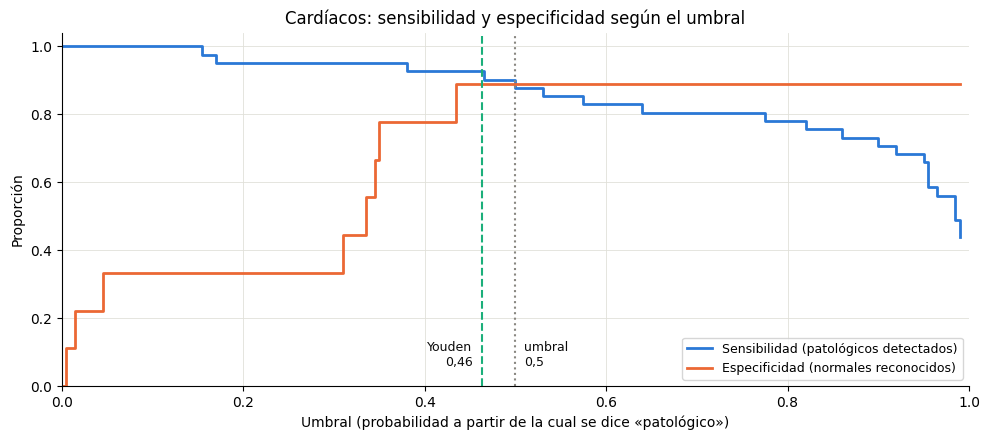

In [11]:
grilla = np.linspace(0, 0.99, 199)   # hasta 0,99: en 1 nada supera el umbral y las curvas saltan
curvas = pd.DataFrame([metricas(y, prob, u) for u in grilla])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.step(grilla, curvas["S"], where="post", color=AZUL, lw=2, label="Sensibilidad (patológicos detectados)")
ax.step(grilla, curvas["E"], where="post", color=NARANJA, lw=2, label="Especificidad (normales reconocidos)")
ax.axvline(0.5, color=GRIS, ls=":", lw=1.5)
ax.text(0.51, 0.06, "umbral\n0,5", color=TINTA, fontsize=9)
ax.axvline(umbral_youden, color=AQUA, ls="--", lw=1.5)
ax.text(umbral_youden - 0.01, 0.06, f"Youden\n{umbral_youden:.2f}".replace(".", ","), color=TINTA, fontsize=9, ha="right")
ax.set(xlim=(0, 1), ylim=(0, 1.04), xlabel="Umbral (probabilidad a partir de la cual se dice «patológico»)",
       ylabel="Proporción", title="Cardíacos: sensibilidad y especificidad según el umbral")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()

Y la **curva ROC** junta todos los umbrales en un solo dibujo: cada punto es un
umbral, con su sensibilidad en el eje vertical y 1 − especificidad (la
proporción de normales mal clasificados) en el horizontal. Moverse sobre la
curva es mover el umbral; **la curva no cambia**, y el AUC es el área debajo de
ella.

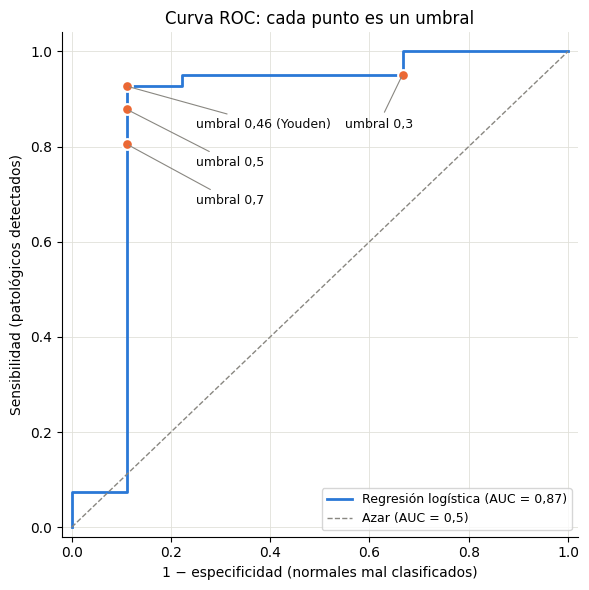

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color=AZUL, lw=2, label=f"Regresión logística (AUC = {roc_auc_score(y, prob):.2f})".replace(".", ","))
ax.plot([0, 1], [0, 1], color=GRIS, lw=1, ls="--", label="Azar (AUC = 0,5)")
for u, texto in [(umbral_youden, (0.25, 0.84)), (0.5, (0.25, 0.76)), (0.7, (0.25, 0.68)), (0.3, (0.55, 0.84))]:
    mu = metricas(y, prob, u)
    punto = (1 - mu["E"], mu["S"])
    ax.scatter(*punto, s=60, color=NARANJA, zorder=3, edgecolor="white", linewidth=1.5)
    nombre = f"{u:.2f} (Youden)" if u == umbral_youden else f"{u:.1f}"
    ax.annotate(f"umbral {nombre}".replace(".", ","), xy=punto, xytext=texto, fontsize=9, color=TINTA,
                arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.8))
ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.04), xlabel="1 − especificidad (normales mal clasificados)",
       ylabel="Sensibilidad (patológicos detectados)", title="Curva ROC: cada punto es un umbral")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()

## 9. El índice de Youden

**Qué es.** Youden (1950) lo propuso para elegir el valor de corte de un test
diagnóstico:

J = sensibilidad + especificidad − 1

- Vale **0** para un test que no sirve (como tirar una moneda: lo que gana en
  sensibilidad lo pierde en especificidad) y **1** para uno perfecto.
- En la curva ROC, J es la **distancia vertical entre el punto y la diagonal
  del azar**. El umbral de Youden es el punto de la curva más alejado de esa
  diagonal.
- Elegir el umbral de Youden es buscar **el mejor equilibrio entre los dos
  errores**, dándoles el mismo peso.

**Con tus números:** el umbral que maximiza J en esta repetición es el de la
fila "Youden" de la tabla: con él se detectan 38 de 41 patológicos y se
reconocen 8 de 9 normales (J ≈ 0,82, contra 0,77 con el umbral de 0,5).

**La relación con la exactitud balanceada.** Como J = S + E − 1 y la exactitud
balanceada es (S + E) / 2, las dos dicen lo mismo en distinta escala:

J = 2 · exactitud balanceada − 1

Maximizar Youden es lo mismo que maximizar la exactitud balanceada. En el
informe que le mandaste, la exactitud balanceada de la regresión logística en
cardíacos con el umbral de 0,5 es **0,783** (promedio de las tres
repeticiones, sección 10): eso corresponde a un Youden de 2 · 0,783 − 1 =
0,566. Es muy probable que tu directora se refiriera a ese número; si no, vale
la pena preguntarle.

**Una advertencia importante.** En esta notebook el umbral de Youden se eligió
mirando las mismas probabilidades con las que se evalúa, así que su resultado
es **optimista**: es como elegir el filtro que mejor dio (notebook 12). En la
tesis (notebook 14) el umbral se elige **dentro de la validación**: en cada
partición se busca con los datos de train y se aplica al test. Por eso ahí el
resultado es más modesto (Tabla 2 del informe: S 0,79 y E 0,70 con Youden).

**Youden no es la única regla.** Si el modelo se usara para tamizaje, no
detectar una patología es peor que un estudio de más, y conviene otra regla:
el umbral más alto que mantenga la sensibilidad en al menos 0,90 (la regla de
"tamizaje" de la notebook 14). Cuál usar es una decisión clínica, que quedó
para charlar con tu directora.

## 10. Las tres repeticiones

Todo lo anterior usó **un** sorteo de las particiones (`random_state=0`). Si se
sortean de nuevo, las grabaciones caen en otros grupos y los números cambian
un poco. Por eso se repite tres veces y se promedia: esos promedios son los del
informe y los de la tesis.

In [13]:
repeticiones = []
for semilla in range(3):
    p = cross_val_predict(modelo, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=semilla), method="predict_proba")[:, 1]
    mr = metricas(y, p, 0.5)
    repeticiones.append({"repetición": semilla + 1, "AUC": mr["AUC"], "S": mr["S"], "E": mr["E"],
                         "exactitud balanceada": mr["exactitud balanceada"]})
repeticiones = pd.DataFrame(repeticiones).set_index("repetición")
repeticiones.loc["promedio"] = repeticiones.mean()
repeticiones.round(3)

,AUC,S,E,exactitud balanceada
repetición,,,,
1,0.867,0.878,0.889,0.883
2,0.827,0.878,0.667,0.772
3,0.786,0.829,0.556,0.692
promedio,0.827,0.862,0.704,0.783


Con 9 normales, **un solo normal mal clasificado cambia la especificidad en
0,11**, así que estas diferencias entre repeticiones son esperables. El
promedio (AUC 0,83, S 0,86, E 0,70, exactitud balanceada 0,78) es la
estimación más estable.

## 11. Ficha para tu directora

Todo lo que pidió el mail, en un solo lugar (se calcula en vivo):

In [14]:
print(f"Modelo:               regresión logística (scikit-learn), C = 1, class_weight = balanced, con escalado")
print(f"Dataset:              HLS-CMDS (Torabi et al., 2025), subconjunto {'cardíaco' if SUBCONJUNTO == 'hs' else 'pulmonar'}")
print(f"Base:                 {X.shape[0]} grabaciones x {X.shape[1]} características")
print(f"Variable a predecir:  0 = normal ({(y == 0).sum()}), 1 = patológico ({(y == 1).sum()})")
print(f"Train / test:         validación cruzada estratificada de 5 particiones, repetida 3 veces;"
      f"\n                      en cada partición, train 40 x {X.shape[1]} y test 10 x {X.shape[1]}")
print(f"Métricas (promedio de 3 repeticiones, umbral 0,5):")
for nombre in ["AUC", "S", "E", "exactitud balanceada"]:
    print(f"   {nombre:<22} {repeticiones.loc['promedio', nombre]:.3f}")

Modelo:               regresión logística (scikit-learn), C = 1, class_weight = balanced, con escalado
Dataset:              HLS-CMDS (Torabi et al., 2025), subconjunto cardíaco
Base:                 50 grabaciones x 101 características
Variable a predecir:  0 = normal (9), 1 = patológico (41)
Train / test:         validación cruzada estratificada de 5 particiones, repetida 3 veces;
                      en cada partición, train 40 x 101 y test 10 x 101
Métricas (promedio de 3 repeticiones, umbral 0,5):
   AUC                    0.827
   S                      0.862
   E                      0.704
   exactitud balanceada   0.783


## 12. Tu turno

1. Elegí un umbral que **no aparezca en la tabla** (por ejemplo, 0,45 o 0,65) y
   calculá sus métricas con `metricas(y, prob, 0.45)`. Antes de correrlo,
   anotá qué esperás que pase con S y E respecto del umbral de 0,5.
2. Cambiá `SUBCONJUNTO = "ls"` en la primera celda de código y volvé a correr
   todo. ¿Qué pasa con el AUC? ¿Y con la tabla de umbrales? ¿Por qué en
   pulmonares el umbral importa mucho menos?
3. El normal que el modelo confunde es `M_N_LLSB` (probabilidad 0,999).
   Escuchalo (como en la notebook 01) junto a `M_N_RUSB`, otro normal del
   mismo caso que el modelo reconoce muy bien (0,003). ¿Suenan distinto? ¿Qué
   podría estar "viendo" el modelo?

In [15]:
metricas(y, prob, 0.45)

{'umbral': 0.45,
 'AUC': 0.8672086720867209,
 'exactitud': np.float64(0.92),
 'S': np.float64(0.926829268292683),
 'E': np.float64(0.8888888888888888),
 'normales reconocidos': '8 de 9',
 'patológicos detectados': '38 de 41',
 'Youden (S + E − 1)': np.float64(0.8157181571815717),
 'exactitud balanceada': np.float64(0.9078590785907859)}

## Preguntas de control

1. ¿Cuántas filas y columnas tiene la base, y qué es cada fila?
2. ¿Cuáles son las categorías de la variable a predecir y cuántas grabaciones
   hay en cada una?
3. ¿Por qué se usa validación cruzada en lugar de una sola división en train y
   test? ¿Qué dimensiones tienen train y test en cada partición?
4. ¿Por qué el escalado va dentro del pipeline?
5. ¿Qué mide el AUC, explicado sin hablar de áreas? ¿Por qué no cambia al
   mover el umbral?
6. Si querés que el modelo reconozca más normales, ¿subís o bajás el umbral?
   ¿Qué perdés?
7. ¿Qué es el índice de Youden y qué relación tiene con la exactitud
   balanceada? ¿A qué Youden corresponde una exactitud balanceada de 0,783?
8. ¿Por qué el umbral de Youden elegido en esta notebook es optimista, y cómo
   se elige en la tesis?
9. ¿Por qué la exactitud no es una buena métrica principal en este conjunto?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** 50 filas por 101 columnas de características (más la etiqueta). Cada
fila es una grabación: un foco de auscultación de un caso del maniquí.

**2.** 0 = normal (9 grabaciones) y 1 = patológico (41), que agrupa nueve tipos
de patología.

**3.** Porque con 9 normales una sola división dejaría 2 normales en el test:
la especificidad solo podría valer 0, 0,5 o 1 y dependería del azar. Con 5
particiones, cada grabación se prueba una vez con un modelo que no la vio. En
cada partición, train tiene 40 × 101 y test 10 × 101.

**4.** Porque la media y el desvío del escalado son información de los datos:
si se calcularan con las 50 grabaciones, el test influiría en el
entrenamiento. Dentro del pipeline se calculan solo con el train de cada
partición.

**5.** La probabilidad de que, tomando al azar una grabación patológica y una
normal, el modelo le dé más probabilidad a la patológica. Solo depende del
orden de las probabilidades, no del corte; por eso es igual con cualquier
umbral.

**6.** Lo subís: hace falta más probabilidad para decir "patológico", así que
más normales quedan como normales (sube E). Perdés sensibilidad: se escapan
más patologías.

**7.** J = S + E − 1: mide cuánto mejor que el azar es el test en un umbral
dado, dándole el mismo peso a los dos errores. Como la exactitud balanceada es
(S + E) / 2, J = 2 · exactitud balanceada − 1. A 0,783 le corresponde J =
0,566.

**8.** Porque se eligió mirando las mismas predicciones con las que se evalúa.
En la tesis se elige con los datos de train de cada partición y se aplica al
test, que no participó de la elección.

**9.** Porque con 82 % de patológicos, decir siempre "patológico" ya da una
exactitud de 0,82 sin reconocer ningún normal. La exactitud balanceada y el
AUC no se dejan engañar así.